In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
df = pd.read_csv("/content/Telco-Customer-Churn.csv")

In [23]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [24]:
print(df.shape)

(7043, 21)


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## **EDA**

In [26]:
print(df["Churn"].value_counts(normalize=True))

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [27]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [28]:
print(df["TotalCharges"].isna().sum())

11


In [29]:
print(df.loc[df["TotalCharges"].isna(), "tenure"].unique())

[0]


In [30]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)                 #because they have never been billed

In [31]:
# Droping the ID column: it's unique per row and has no predictive value
df = df.drop(columns="customerID")

In [32]:
# Build the target and the features
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns="Churn")

In [33]:
print(X.dtypes.value_counts())

object     15
int64       2
float64     2
Name: count, dtype: int64


In [37]:
print(y.mean())

0.2653698707936959


In [35]:
# Churn rate by key categorical features
for col in ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport"]:
    print(df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).round(3), "\n")

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64 

InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64 

PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Electronic check             0.453
Mailed check                 0.191
Name: Churn, dtype: float64 

OnlineSecurity
No                     0.418
No internet service    0.074
Yes                    0.146
Name: Churn, dtype: float64 

TechSupport
No                     0.416
No internet service    0.074
Yes                    0.152
Name: Churn, dtype: float64 



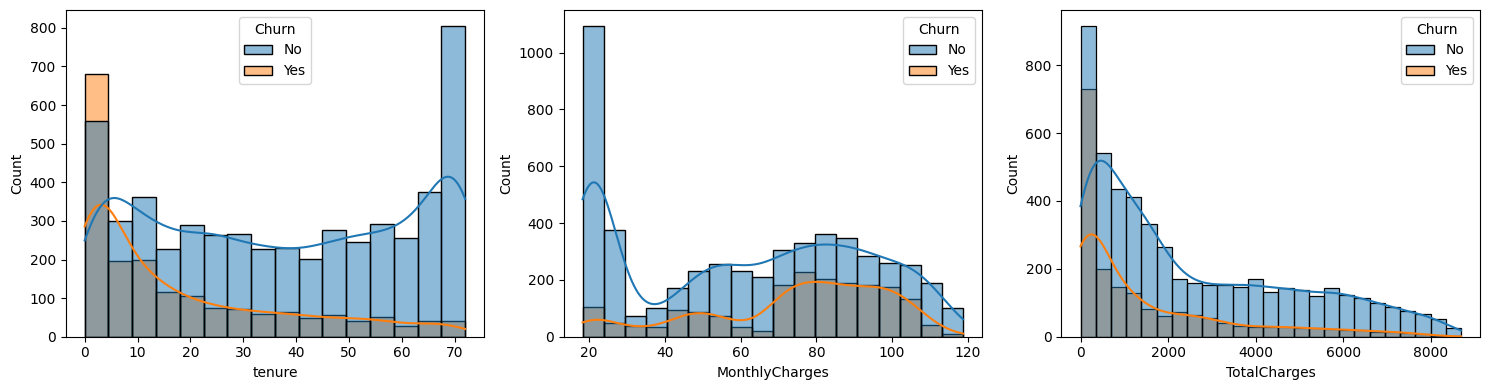

In [36]:
# Numeric features vs churn
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=ax)
plt.tight_layout(); plt.show()

In [38]:
# Correlation among numeric features
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].corr())

                  tenure  MonthlyCharges  TotalCharges
tenure          1.000000        0.247900      0.826178
MonthlyCharges  0.247900        1.000000      0.651174
TotalCharges    0.826178        0.651174      1.000000


Analysis So Far:
“New, month-to-month, fiber-optic customers paying by electronic check without support services are the highest-risk group.”

In [39]:
from sklearn.model_selection import train_test_split

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [41]:
print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


In [42]:
print(y_train.mean(), y_test.mean())

0.2653532126375577 0.2654364797728886


In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [44]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

In [45]:
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [48]:
# fit_transform on TRAIN: learns the scaling/encoding rules AND applies them
X_train_p = pre.fit_transform(X_train)

# transform on TEST: only applies the rules learned from train
X_test_p = pre.transform(X_test)

print(X_train.shape, "->", X_train_p.shape)   # 19 columns become ~40 after one-hot
print(X_test.shape, "->", X_test_p.shape)

(5634, 19) -> (5634, 46)
(1409, 19) -> (1409, 46)


## **Handling Balance**

In [53]:
from imblearn.over_sampling import SMOTE

print("Before:", np.bincount(y_train))     # roughly [4139, 1495]

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_p, y_train)

print("After: ", np.bincount(y_train_bal)) # roughly [4139, 4139]

Before: [4139 1495]
After:  [4139 4139]


## **Building Models**

In [50]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

In [51]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_bal, y_train_bal)
print("LogReg test AUC:", roc_auc_score(y_test, lr.predict_proba(X_test_p)[:, 1]))

LogReg test AUC: 0.8399493657805678


In [52]:
xgb = XGBClassifier(eval_metric="logloss", random_state=42)
xgb.fit(X_train_bal, y_train_bal)
print("XGB test AUC:", roc_auc_score(y_test, xgb.predict_proba(X_test_p)[:, 1]))

XGB test AUC: 0.8207354878710378


In [54]:
from sklearn.metrics import classification_report

# Probabilities of churn, then hard labels at the default 0.5 threshold
proba_xgb = xgb.predict_proba(X_test_p)[:, 1]
pred_xgb = (proba_xgb >= 0.5).astype(int)

print(classification_report(y_test, pred_xgb, target_names=["No churn", "Churn"]))

              precision    recall  f1-score   support

    No churn       0.85      0.85      0.85      1035
       Churn       0.59      0.59      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409



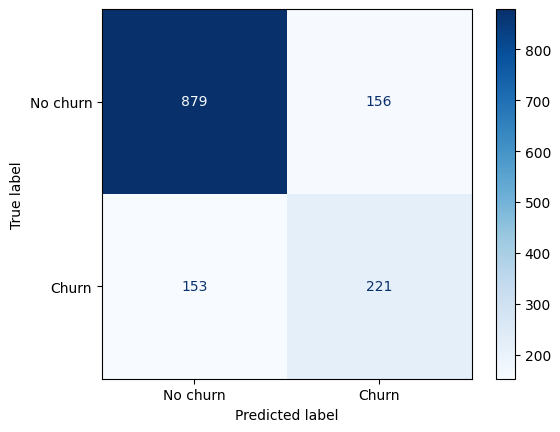

In [55]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, pred_xgb)
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(cmap="Blues")
plt.show()

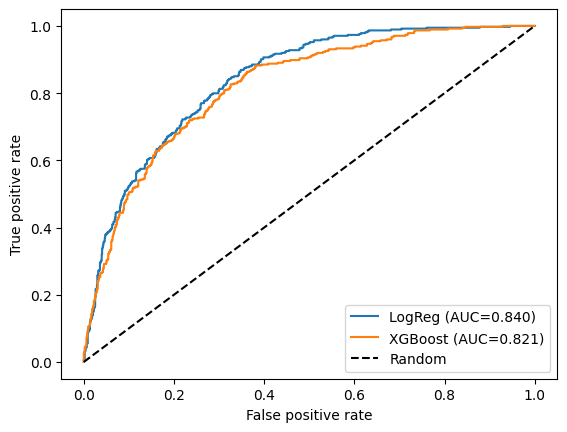

In [57]:
from sklearn.metrics import roc_curve, roc_auc_score

proba_lr = lr.predict_proba(X_test_p)[:, 1]

for name, p in [("LogReg", proba_lr), ("XGBoost", proba_xgb)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.legend(); plt.show()

In [56]:
from sklearn.metrics import precision_score, recall_score, f1_score

for t in [0.3, 0.4, 0.5, 0.6]:
    pred = (proba_xgb >= t).astype(int)
    print(f"threshold={t}  precision={precision_score(y_test, pred):.2f}  "
          f"recall={recall_score(y_test, pred):.2f}  f1={f1_score(y_test, pred):.2f}")

threshold=0.3  precision=0.52  recall=0.72  f1=0.60
threshold=0.4  precision=0.55  recall=0.66  f1=0.60
threshold=0.5  precision=0.59  recall=0.59  f1=0.59
threshold=0.6  precision=0.63  recall=0.51  f1=0.56
